# 01 — Building the benchmark population, and red-teaming it

**Question this notebook answers:** is the IRS Form 990 population a trustworthy stand-in for a real
annual survey of non-profit organisations, and where could it mislead us about the value of text
embeddings?

**Scenario being mimicked.** A statistical agency runs an annual survey of non-profits for reference
year *t* = tax year 2023. At design time it holds a register (the frame) built from tax year
*t − 1* = 2022: industry code (NTEE), state, subsection, ruling year, last year's revenue / expenses /
assets / employees, and last year's free-text mission and program descriptions. The survey collects
year-*t* values. Here every non-profit's year-*t* return is known, so the "survey" can be re-drawn
thousands of times and every estimator compared against the truth.

| Role | Real agency source | Here |
|---|---|---|
| Frame codes | business register (NAICS, province, size) | IRS Business Master File snapshot **2023-08-16** |
| Lagged admin size | prior-year tax data | TY2022 Form 990 Part I |
| Frame text | registration "nature of business" text, charity-register program descriptions | TY2022 mission (Part I l.1, Part III l.1) and program descriptions (Part III 4a–4d) |
| Survey values | questionnaire | TY2023 Form 990 |
| Nonresponse | late / non-returned questionnaires | TY2023 return filed > 300 days after fiscal year end |

Each check below prints a number and a pass / warn / fail verdict; the summary table is at the end.

In [1]:
import os, re, sys, glob, gzip, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

PROJ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(PROJ, "src"))
DATA = os.environ.get("EMBAUX_DATA", "/tmp/claude-0/data")
REGION = os.environ.get("EMBAUX_REGION", "ne")
import plotstyle; plotstyle.use()
from embed import load as load_emb
from experiments import impute_ntee, text_groups

pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
checks = []
def check(test, value, verdict, note=""):
    checks.append({"test": test, "value": value, "verdict": verdict, "note": note})
    print(f"[{verdict:4s}] {test}: {value}  {note}")

pop = pd.read_parquet(f"{DATA}/pop/{REGION}_pop.parquet")
prev = pd.read_parquet(f"{DATA}/parsed/{REGION}_2022.parquet")
curr = pd.read_parquet(f"{DATA}/parsed/{REGION}_2023.parquet")
edits = pd.read_csv(f"{DATA}/pop/{REGION}_pop_editlog.csv")
print("population", pop.shape, "| TY2022 filers", len(prev), "| TY2023 filers", len(curr))

population (20626, 53) | TY2022 filers 21741 | TY2023 filers 22040


## 1. Population flow and unit definition
One unit = one EIN (employer identification number). For each (EIN, tax year) we keep the most recently submitted
non-group full Form 990. Continuing units (filed both years) form the population; deaths and births
are the frame-coverage error a real survey would face.

In [2]:
births = len(set(curr.ein) - set(prev.ein)); deaths = len(set(prev.ein) - set(curr.ein))
flow = pd.DataFrame({"count": [len(prev), deaths, len(pop), births, len(curr)]},
                    index=["frame: TY2022 full-990 filers", "deaths (no TY2023 return)", "population U (both years)",
                           "births (TY2023 only; frame undercoverage)", "TY2023 filers"])
display(flow)
check("one row per EIN", int(pop.ein.duplicated().sum()), "pass" if pop.ein.is_unique else "fail")
check("frame undercoverage of TY2023 filers (births)", f"{births / len(curr):.1%}", "info",
      "births are excluded from U; a real survey would need a birth stratum")
# expenses share of births / deaths, to see whether coverage error is about small units
exp_b = curr[~curr.ein.isin(prev.ein)].expenses_cy.sum() / curr.expenses_cy.sum()
check("expense share of births", f"{exp_b:.2%}", "pass" if exp_b < 0.05 else "warn")

,count
frame: TY2022 full-990 filers,21741
deaths (no TY2023 return),1115
population U (both years),20626
births (TY2023 only; frame undercoverage),1414
TY2023 filers,22040


[pass] one row per EIN: 0  
[info] frame undercoverage of TY2023 filers (births): 6.4%  births are excluded from U; a real survey would need a birth stratum


[pass] expense share of births: 0.30%  


## 2. Timing: is every frame variable really available at design time?
The classic trap is to take frame codes from a *current* Business Master File, whose amounts already come from
the target year's returns. We compare our 2023-08 snapshot with a 2026 snapshot.

In [3]:
def bmf_leak(path):
    b = pd.read_csv(path, dtype=str, usecols=["EIN", "REVENUE_AMT", "INCOME_AMT", "TAX_PERIOD"])
    m = pop[["ein", "y_revenue"]].merge(b, left_on="ein", right_on="EIN", how="left")
    rev = pd.to_numeric(m.REVENUE_AMT, errors="coerce")
    return float((rev == m.y_revenue).mean()), m.TAX_PERIOD.str[:4].value_counts().head(4).to_dict()
leak_23, tp_23 = bmf_leak(f"{DATA}/raw990/bmf_2023_8_16.csv")
check("BMF 2023-08 REVENUE_AMT equals target-year revenue", f"{leak_23:.2%}", "pass" if leak_23 < 0.01 else "fail",
      f"tax periods behind the snapshot's amounts: {tp_23}")
if os.path.exists(f"{DATA}/raw990/bmf_2026_5_28.csv"):
    leak_26, tp_26 = bmf_leak(f"{DATA}/raw990/bmf_2026_5_28.csv")
    check("CONTRAST: BMF 2026-05 REVENUE_AMT equals target-year revenue", f"{leak_26:.2%}", "info",
          "this is the leak a careless frame build would introduce")
check("text taken from the t-1 return only", sorted(prev.tax_year.unique().tolist()),
      "pass" if set(prev.tax_year.unique()) == {2022.0} else "fail")

[pass] BMF 2023-08 REVENUE_AMT equals target-year revenue: 0.48%  tax periods behind the snapshot's amounts: {'2022': 12594, '2021': 7227, '2020': 209, '2023': 171}


[info] CONTRAST: BMF 2026-05 REVENUE_AMT equals target-year revenue: 22.77%  this is the leak a careless frame build would introduce
[pass] text taken from the t-1 return only: [2022.0]  


## 3. Frame quality: industry codes, geography

In [4]:
size_cls = pd.qcut(pop.lag_expenses.rank(method="first"), 4, labels=["Q1 small", "Q2", "Q3", "Q4 large"])
miss = pop.ntee_major10.eq("MISSING")
check("NTEE missing on the frame", f"{miss.mean():.1%}", "warn" if miss.mean() > 0.1 else "pass",
      "kept as its own stratification level; a text-coded NTEE arm is tested")
display(pd.DataFrame({"NTEE missing": miss.groupby(size_cls, observed=True).mean().round(3)}).T)
agree = (pop.state == curr.set_index("ein").loc[pop.ein, "legal_domicile_state"].fillna(curr.set_index("ein").loc[pop.ein, "state_addr"]).to_numpy()).mean()
check("state agrees between t-1 and t returns", f"{agree:.1%}", "pass" if agree > 0.98 else "warn")

[warn] NTEE missing on the frame: 31.1%  kept as its own stratification level; a text-coded NTEE arm is tested


lag_expenses,Q1 small,Q2,Q3,Q4 large
NTEE missing,0.379,0.324,0.283,0.258


[pass] state agrees between t-1 and t returns: 99.9%  


## 4. Survey-variable (y) quality
Truth is "the value as reported, after narrow edit rules for gross errors". Influential but plausible values
(e.g. FIRST Robotics' 430k volunteers) are kept. They are a realistic challenge, not an error.

In [5]:
display(edits.rule.value_counts().to_frame("units edited"))
ycols = ["y_expenses", "y_revenue", "y_employees", "y_salaries", "y_gov_grants", "y_prog_rev", "y_contrib",
         "y_fundraising_exp", "y_officer_comp", "y_volunteers", "y_volunteers_cap10k"]
def top_share(v, q=0.01):
    v = np.sort(v)[::-1]; return v[: max(1, int(q * len(v)))].sum() / v.sum()
yq = pd.DataFrame({
    "total": pop[ycols].sum(), "share zero": (pop[ycols] == 0).mean(),
    "top 1% share": [top_share(pop[c].to_numpy()) for c in ycols],
    "CV across units": pop[ycols].std() / pop[ycols].mean(),
}).round(3)
display(yq)
vol_blank = curr.set_index("ein").loc[pop.ein, "volunteers"].isna().mean()
v = pop.y_volunteers[pop.y_volunteers > 0]
heap = {k: float((v % k == 0).mean()) for k in (10, 50, 100)}
check("volunteers: blank (treated as 0)", f"{vol_blank:.1%}", "warn", "blank vs true zero is not distinguishable")
check("volunteers: heaping on multiples of 10/50/100", {k: f"{x:.0%}" for k, x in heap.items()}, "warn",
      "reported volunteer counts are rough guesses; expect noisy y")
cons = (curr.set_index("ein").loc[pop.ein, "revenue_py"].to_numpy() == pop.lag_revenue.to_numpy()).mean()
check("PY revenue on t return equals CY revenue on t-1 return", f"{cons:.1%}", "pass" if cons > 0.95 else "warn",
      "restatements are rare")
idx_ok = (curr.revenue_cy.fillna(0).round() == pd.to_numeric(curr.TotalRevenueCY, errors="coerce").fillna(0).round()).mean()
check("parsed revenue equals GivingTuesday index revenue", f"{idx_ok:.2%}", "pass" if idx_ok > 0.99 else "fail")
amend = pop.amended_t.mean(); amend_e = pop.y_expenses[pop.amended_t == 1].sum() / pop.y_expenses.sum()
check("truth taken from amended returns", f"{amend:.1%} of units, {amend_e:.1%} of expenses", "info")
fye = pop.tax_period_end_t.dt.month.value_counts(normalize=True).head(4).round(3).to_dict()
check("fiscal-year-end month mix (t)", fye, "info", "reference periods differ across units, as in real business surveys")

,units edited
rule,
E3_filing_delay,154
E1_employees,3
E2_negative_y_expenses,3
E2_negative_y_gov_grants,1
E2_negative_y_prog_rev,1
E2_negative_y_grants_paid,1


,total,share zero,top 1% share,CV across units
y_expenses,2.725785e+11,0.007,0.675,12.468
y_revenue,2.902744e+11,0.007,0.681,13.976
y_employees,1.644920e+06,0.369,0.514,8.673
y_salaries,1.016843e+11,0.287,0.618,11.032
y_gov_grants,1.934544e+10,0.689,0.652,12.869
y_prog_rev,1.965533e+11,0.307,0.726,11.753
y_contrib,6.397328e+10,0.192,0.670,36.945
y_fundraising_exp,2.955601e+09,0.615,0.608,14.785
y_officer_comp,4.016830e+09,0.507,0.345,4.965
y_volunteers,4.944496e+06,0.413,0.819,62.936


[warn] volunteers: blank (treated as 0): 19.7%  blank vs true zero is not distinguishable
[warn] volunteers: heaping on multiples of 10/50/100: {10: '32%', 50: '13%', 100: '7%'}  reported volunteer counts are rough guesses; expect noisy y
[pass] PY revenue on t return equals CY revenue on t-1 return: 97.9%  restatements are rare
[pass] parsed revenue equals GivingTuesday index revenue: 100.00%  
[info] truth taken from amended returns: 1.5% of units, 0.9% of expenses  
[info] fiscal-year-end month mix (t): {12: 0.472, 6: 0.328, 9: 0.079, 8: 0.034}  reference periods differ across units, as in real business surveys


## 5. Text quality and leakage
Three questions. Is there usable text for everyone? Does the text quietly state the target? Is the text a stable
description (between-unit signal) or does it track year-to-year change?

In [6]:
w = pop.text_full.str.split().str.len()
uninf = pop.text_mission.str.strip().str.lower().isin(["", "see schedule o", "see statement", "none", "n/a"]) | (pop.text_mission.str.split().str.len() < 3)
check("uninformative mission text (empty / 'see schedule o' / < 3 words)", f"{uninf.mean():.1%}", "warn" if uninf.mean() > 0.02 else "pass")
display(pd.DataFrame({"uninformative mission": uninf.groupby(size_cls, observed=True).mean().round(3),
                      "median words (full text)": w.groupby(size_cls, observed=True).median()}).T)
g = text_groups(pop); dup = pd.Series(g).map(pd.Series(g).value_counts()) > 1
check("units sharing an identical mission text (chapters, templates)", f"{dup.mean():.1%}", "warn",
      "cross-fitting uses grouped folds so duplicates cannot leak across folds")
digit = pop.text_full.str.contains(r"\d"); dollar = pop.text_full.str.contains(r"\$")
check("text containing any digit / '$'", f"{digit.mean():.1%} / {dollar.mean():.1%}", "info",
      "numbers-masked variant is embedded to test whether gains come from numbers")
def contains_value(texts, vals):
    out = []
    for t, v in zip(texts, vals):
        if v is None or not np.isfinite(v) or v < 1000:
            out.append(False); continue
        s1, s2 = f"{int(round(v))}", f"{int(round(v)):,}"
        out.append((s1 in t) or (s2 in t))
    return np.array(out)
for yc in ["y_expenses", "y_revenue", "y_gov_grants"]:
    hit = contains_value(pop.text_full.tolist(), pop[yc].tolist())
    check(f"text states the exact target value ({yc})", f"{hit.mean():.3%}", "pass" if hit.mean() < 0.01 else "fail")
same = (pop.text_mission.str.upper() == pop.text_mission_t.str.upper())
check("mission text identical in t-1 and t", f"{same.mean():.1%}", "info",
      "text is a near-static description: expect between-unit signal, not change signal")

[warn] uninformative mission text (empty / 'see schedule o' / < 3 words): 2.1%  


lag_expenses,Q1 small,Q2,Q3,Q4 large
uninformative mission,0.028,0.025,0.019,0.014
median words (full text),51.000,60.000,76.000,128.000


[warn] units sharing an identical mission text (chapters, templates): 4.8%  cross-fitting uses grouped folds so duplicates cannot leak across folds
[info] text containing any digit / '$': 44.1% / 3.8%  numbers-masked variant is embedded to test whether gains come from numbers
[pass] text states the exact target value (y_expenses): 0.000%  
[pass] text states the exact target value (y_revenue): 0.005%  


[pass] text states the exact target value (y_gov_grants): 0.005%  
[info] mission text identical in t-1 and t: 84.5%  text is a near-static description: expect between-unit signal, not change signal


## 6. Coverage: which units have richer text (websites)?
If richer auxiliary text exists mainly for large units, any website-based method inherits a size-graded
coverage gap, as ISTAT found for enterprise websites.

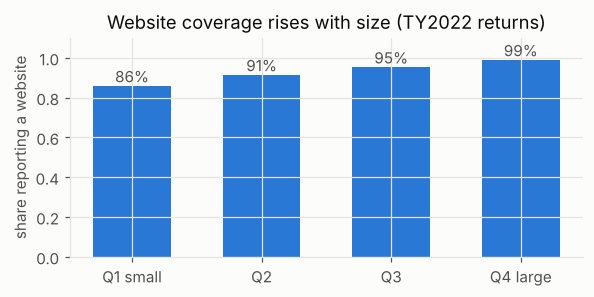

In [7]:
web = pop.has_website.groupby(size_cls, observed=True).mean()
fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.bar(web.index.astype(str), web.values, width=0.6, color=plotstyle.SERIES[0])
for i, v_ in enumerate(web.values):
    ax.text(i, v_ + 0.02, f"{v_:.0%}", ha="center", color=plotstyle.TEXT2)
ax.set_ylim(0, 1.1); ax.set_ylabel("share reporting a website"); ax.set_title("Website coverage rises with size (TY2022 returns)")
plt.tight_layout(); plt.show()

## 7. The nonresponse mechanism (late filers)
"Respondents" are units whose TY2023 return was submitted within 300 days of fiscal year end. This mechanism is
real behaviour, not simulated. It is strongly size-graded, because large organisations file on extension.

In [8]:
resp = pop.days_to_file_t <= 300
check("response rate (unit / expense-weighted)", f"{resp.mean():.1%} / {(pop.lag_expenses * resp).sum() / pop.lag_expenses.sum():.1%}", "info")
display(pd.DataFrame({"response rate": resp.groupby(size_cls, observed=True).mean().round(3)}).T)
ratio = {c: round(pop.loc[resp, c].mean() / pop.loc[~resp, c].mean(), 2) for c in
         ["y_expenses", "y_gov_grants", "y_contrib", "y_fundraising_exp", "y_volunteers_cap10k", "y_bin_lobbying", "y_bin_has_gov_grants"]}
display(pd.Series(ratio, name="respondent mean / nonrespondent mean").to_frame().T)

[info] response rate (unit / expense-weighted): 60.1% / 18.4%  


lag_expenses,Q1 small,Q2,Q3,Q4 large
response rate,0.681,0.637,0.583,0.504


,y_expenses,y_gov_grants,y_contrib,y_fundraising_exp,y_volunteers_cap10k,y_bin_lobbying,y_bin_has_gov_grants
respondent mean / nonrespondent mean,0.15,0.44,0.25,0.35,0.77,0.48,0.89


## 8. Embedding sanity checks
These checks need no y. Can text recover the industry code? Do neighbours look sensible? Then two y-based controls:
a **placebo** y that text cannot know, and a **memorisation probe**, where text should not predict year-over-year change.

In [9]:
emb_names = [os.path.basename(p)[:-4] for p in sorted(glob.glob(f"{DATA}/emb/{REGION}/*.npy"))]
print("embeddings available:", emb_names)
for nm in [n for n in emb_names if n in ("lsa256_full", "minilm_mission", "minilm_full")]:
    E = load_emb(f"{DATA}/emb/{REGION}", nm)[0]
    _, acc = impute_ntee(pop, E)
    check(f"text-coded NTEE accuracy, 10 groups ({nm})", f"{acc:.1%}", "info", "chance (largest class) is about 24%")

embeddings available: ['lsa256_full', 'lsa256_mission', 'minilm_full', 'minilm_mission']


[info] text-coded NTEE accuracy, 10 groups (lsa256_full): 70.1%  chance (largest class) is about 24%


[info] text-coded NTEE accuracy, 10 groups (minilm_full): 71.1%  chance (largest class) is about 24%


[info] text-coded NTEE accuracy, 10 groups (minilm_mission): 69.3%  chance (largest class) is about 24%


In [10]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import cross_val_predict
from frame import pcs
rng = np.random.default_rng(0)
def pop_r2(F, y):
    p = cross_val_predict(RidgeCV(alphas=np.logspace(-2, 3, 8)), F, y, cv=5)
    return 1 - np.mean((y - p) ** 2) / np.var(y)
strata_key = pop.ntee_major10.astype(str) + pd.qcut(pop.lag_expenses.rank(method="first"), 5, labels=False).astype(str)
S = pd.get_dummies(strata_key, dtype=float).to_numpy()
y_real = np.log1p(pop.y_gov_grants.to_numpy())
y_placebo = np.log1p(pop.groupby(strata_key)["y_gov_grants"].transform(lambda s: s.sample(frac=1, random_state=1).to_numpy()).to_numpy())
y_change = (np.log1p(pop.y_revenue.clip(lower=0)) - np.log1p(pop.lag_revenue.clip(lower=0))).to_numpy()
base = {"real": pop_r2(S, y_real), "placebo": pop_r2(S, y_placebo), "change": pop_r2(S, y_change)}
rows = []
for nm in [n for n in emb_names if n in ("lsa256_full", "minilm_mission", "minilm_full", "random384")]:
    Z, _ = pcs(load_emb(f"{DATA}/emb/{REGION}", nm)[0].astype(float), 64)
    F = np.c_[S, Z]
    rows.append({"embedding": nm,
                 "incremental R2 over strata: log gov grants": pop_r2(F, y_real) - base["real"],
                 "incremental R2: placebo (shuffled within strata)": pop_r2(F, y_placebo) - base["placebo"],
                 "incremental R2: revenue change (memorisation probe)": pop_r2(F, y_change) - base["change"]})
probe = pd.DataFrame(rows).round(4); display(probe)
for _, r in probe.iterrows():
    v_pl = r["incremental R2: placebo (shuffled within strata)"]
    check(f"placebo y gains nothing from text ({r.embedding})", v_pl, "pass" if v_pl < 0.005 else "fail")
    v_ch = r["incremental R2: revenue change (memorisation probe)"]
    check(f"memorisation probe: text predicts revenue change ({r.embedding})", v_ch, "info" if v_ch < 0.05 else "warn",
          "compare across models; a jump for an API model would suggest it has seen post-2023 web data")

,embedding,incremental R2 over strata: log gov grants,incremental R2: placebo (shuffled within strata),incremental R2: revenue change (memorisation probe)
0,lsa256_full,0.1494,-0.0040,-0.0036
1,minilm_full,0.1256,-0.0037,-0.0026
2,minilm_mission,0.0968,-0.0030,-0.0037


[pass] placebo y gains nothing from text (lsa256_full): -0.004  
[info] memorisation probe: text predicts revenue change (lsa256_full): -0.0036  compare across models; a jump for an API model would suggest it has seen post-2023 web data
[pass] placebo y gains nothing from text (minilm_full): -0.0037  
[info] memorisation probe: text predicts revenue change (minilm_full): -0.0026  compare across models; a jump for an API model would suggest it has seen post-2023 web data
[pass] placebo y gains nothing from text (minilm_mission): -0.003  
[info] memorisation probe: text predicts revenue change (minilm_mission): -0.0037  compare across models; a jump for an API model would suggest it has seen post-2023 web data


## Summary of checks

In [11]:
summary = pd.DataFrame(checks)
display(summary)
os.makedirs(os.path.join(PROJ, "results"), exist_ok=True)
summary.to_csv(os.path.join(PROJ, "results", f"01_red_team_checks_{REGION}.csv"), index=False)

,test,value,verdict,note
0,one row per EIN,0,pass,
1,frame undercoverage of TY2023 filers (births),6.4%,info,births are excluded from U; a real survey would need a birth stratum
2,expense share of births,0.30%,pass,
3,BMF 2023-08 REVENUE_AMT equals target-year revenue,0.48%,pass,"tax periods behind the snapshot's amounts: {'2022': 12594, '2021': 7227, '20..."
4,CONTRAST: BMF 2026-05 REVENUE_AMT equals target-year revenue,22.77%,info,this is the leak a careless frame build would introduce
5,text taken from the t-1 return only,[2022.0],pass,
6,NTEE missing on the frame,31.1%,warn,kept as its own stratification level; a text-coded NTEE arm is tested
7,state agrees between t-1 and t returns,99.9%,pass,
8,volunteers: blank (treated as 0),19.7%,warn,blank vs true zero is not distinguishable
9,volunteers: heaping on multiples of 10/50/100,"{10: '32%', 50: '13%', 100: '7%'}",warn,reported volunteer counts are rough guesses; expect noisy y
